# RNA model testing and post-processing

This notebook evaluates a reconstruction-only FoldingNet trained on the yjdf apo and holo RNA ensembles. It reuses the checkpoint normalization, compares reconstruction RMSD, visualizes latent space and compactness, and writes a linear apo-to-holo transition path.

In [1]:
from pathlib import Path
import csv
import json
import numpy as np
import matplotlib.pyplot as plt
import torch

from molearn.data import PDBData_RNA
from molearn.models.foldingnet import AutoEncoder
from molearn.analysis import MolearnAnalysis, add_connect_directory_RNA
from molearn.analysis.path import oversample
import json

print('PyTorch:', torch.__version__)
print('CUDA:', torch.cuda.is_available())

PyTorch: 2.14.0+cu130
CUDA: True


## Configuration

Choose `CTI` or `LUM`. `frame_step=10` evaluates 2,500 frames from each ensemble; increase it for a quicker test.

In [2]:
model_ensembles = ['apo', 'CTI', 'LUM'] #['apo', 'CTI']  # use ['apo', 'CTI', 'LUM'] for the three-state model
holo_state = 'CTI'  # pairwise endpoint to analyze: 'CTI' or 'LUM'
frame_step = 10
batch_size = 16

cwd = Path.cwd().resolve()
repo_root = cwd.parent if cwd.name == 'examples' else cwd
examples_dir = repo_root / 'examples'
non_apo_RNA = [name for name in model_ensembles if name.lower() != 'apo']
model_name_RNA = '_'.join(non_apo_RNA or model_ensembles)
analysis_name_RNA = model_name_RNA if model_name_RNA == holo_state else f'{model_name_RNA}_{holo_state}'
output_dir = examples_dir / f'analysis_RNA_{analysis_name_RNA}'
output_dir.mkdir(parents=True, exist_ok=True)

manifest_path_RNA = examples_dir / 'rna_ensembles.json'
with open(manifest_path_RNA) as infile_RNA:
    manifest_RNA = json.load(infile_RNA)
if holo_state not in model_ensembles or 'apo' not in model_ensembles:
    raise ValueError('Both apo and holo_state must occur in model_ensembles')
def manifest_path_value_RNA(state_RNA, field_RNA):
    path_RNA = Path(manifest_RNA[state_RNA][field_RNA]).expanduser()
    return path_RNA if path_RNA.is_absolute() else repo_root / path_RNA
apo_topology = manifest_path_value_RNA('apo', 'topology')
apo_trajectory = manifest_path_value_RNA('apo', 'trajectory')
holo_topology = manifest_path_value_RNA(holo_state, 'topology')
holo_trajectory = manifest_path_value_RNA(holo_state, 'trajectory')

for path in [apo_topology, apo_trajectory, holo_topology, holo_trajectory]:
    if not path.exists():
        raise FileNotFoundError(path)

print('Repository:', repo_root)
print('Output:', output_dir)

Repository: /home/naeim/Workspace/Edinburgh/GitHub/molearn
Output: /home/naeim/Workspace/Edinburgh/GitHub/molearn/examples/analysis_RNA_CTI_LUM_CTI


## Load the checkpoint

The converged checkpoint is preferred. If training was limited to a fixed number of epochs, the notebook falls back to `last.ckpt`.

In [3]:
checkpoint_dir = examples_dir / f'foldingnet_RNA_{model_name_RNA}_aligned_checkpoints'
statistics_path = examples_dir / f'data_statistics_RNA_{model_name_RNA}_aligned.json'
converged = checkpoint_dir / 'checkpoint_converged.ckpt'
last = checkpoint_dir / 'last.ckpt'
checkpoint_path = converged if converged.exists() else last
if not checkpoint_path.exists():
    raise FileNotFoundError(f'No checkpoint found in {checkpoint_dir}')
if not statistics_path.exists():
    raise FileNotFoundError(f'No RNA alignment statistics found at {statistics_path}')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
with open(statistics_path) as infile:
    statistics_RNA = json.load(infile)
alignment_reference_RNA = np.asarray(statistics_RNA['alignment_reference_RNA'])
out_points = checkpoint['network_kwargs']['out_points']

model_RNA = AutoEncoder(**checkpoint['network_kwargs']).to(device)
model_RNA.load_state_dict(checkpoint['model_state_dict'])
model_RNA.eval()

print('Checkpoint:', checkpoint_path)
print('Epoch:', checkpoint.get('epoch'))
print('Expected points:', out_points)
print('Device:', device)

Checkpoint: /home/naeim/Workspace/Edinburgh/GitHub/molearn/examples/foldingnet_RNA_CTI_LUM_aligned_checkpoints/checkpoint_converged.ckpt
Epoch: 74
Expected points: 480
Device: cuda


## Select the representation used during training

The original RNA example used 192 `P/C4′` points. The extended representation uses five sites per nucleotide and therefore 480 points. The checkpoint determines which selection is used.

In [4]:
selection_192_RNA = "resname A C G U A3 and (name P or name C4')"
selection_480_RNA = """
((resname A G A3) and (name P or name C4' or name N9 or name C2 or name C6))
or
((resname C U) and (name P or name C4' or name N1 or name C2 or name C4))
"""

if out_points == 192:
    selection_RNA = selection_192_RNA
elif out_points == 480:
    selection_RNA = selection_480_RNA
else:
    raise ValueError(f'No RNA selection is defined for {out_points} points')

print(selection_RNA)


((resname A G A3) and (name P or name C4' or name N9 or name C2 or name C6))
or
((resname C U) and (name P or name C4' or name N1 or name C2 or name C4))



## Load apo and holo independently

Both datasets use the mean and standard deviation stored in the checkpoint. They must not be normalized independently.

In [5]:
def load_ensemble_RNA(topology, trajectory):
    data = PDBData_RNA()
    data.import_pdb_RNA(str(trajectory), topology=str(topology))
    data.atomselect_RNA(selection_RNA)
    data.prepare_dataset_RNA(
        mean=checkpoint['mean'],
        std=checkpoint['std'],
        step=frame_step,
        align_RNA=True,
        alignment_reference_RNA=alignment_reference_RNA,
    )
    if data.dataset.shape[1] != out_points:
        raise ValueError(
            f'Data has {data.dataset.shape[1]} points; checkpoint expects {out_points}'
        )
    return data

data_apo_RNA = load_ensemble_RNA(apo_topology, apo_trajectory)
data_holo_RNA = load_ensemble_RNA(holo_topology, holo_trajectory)

print('Apo:', tuple(data_apo_RNA.dataset.shape))
print('Holo:', tuple(data_holo_RNA.dataset.shape))

Using pre-computed mean: -0.14146670735272998, std: 15.294030443512792
RNA dataset shape: torch.Size([2500, 480, 3])
Using pre-computed mean: -0.14146670735272998, std: 15.294030443512792
RNA dataset shape: torch.Size([2500, 480, 3])
Apo: (2500, 480, 3)
Holo: (2500, 480, 3)


## Register datasets for analysis

In [6]:
analysis_RNA = MolearnAnalysis()
analysis_RNA.set_network(model_RNA)
analysis_RNA.batch_size = batch_size
analysis_RNA.set_dataset(data=data_apo_RNA, key='apo')
analysis_RNA.set_dataset(data=data_holo_RNA, key='holo')

print('Trainable parameters:', analysis_RNA.num_trainable_params())

Trainable parameters: 10438208


## Reconstruction RMSD

Each input is encoded, decoded, aligned to its reconstruction, and measured in ångströms.

In [7]:
rmsd_apo_RNA = analysis_RNA.get_error('apo')
rmsd_holo_RNA = analysis_RNA.get_error('holo')

def summarize_RNA(label, values):
    return {
        'ensemble': label,
        'frames': len(values),
        'mean_rmsd_A': float(np.mean(values)),
        'median_rmsd_A': float(np.median(values)),
        'p95_rmsd_A': float(np.percentile(values, 95)),
        'max_rmsd_A': float(np.max(values)),
    }

summary_RNA = [
    summarize_RNA('apo', rmsd_apo_RNA),
    summarize_RNA('holo', rmsd_holo_RNA),
]
for row in summary_RNA:
    print(row)

with open(output_dir / 'reconstruction_summary.csv', 'w', newline='') as handle:
    writer = csv.DictWriter(handle, fieldnames=summary_RNA[0].keys())
    writer.writeheader()
    writer.writerows(summary_RNA)

encoding apo: 157it [00:01, 116.36it/s]
Decoding apo: 157it [00:01, 141.99it/s]
encoding holo: 157it [00:01, 139.23it/s]
Decoding holo: 157it [00:00, 165.54it/s]


{'ensemble': 'apo', 'frames': 2500, 'mean_rmsd_A': 2.2635670202004423, 'median_rmsd_A': 2.1729004977422006, 'p95_rmsd_A': 3.302106962598562, 'max_rmsd_A': 6.329224441529152}
{'ensemble': 'holo', 'frames': 2500, 'mean_rmsd_A': 2.3606101938526147, 'median_rmsd_A': 2.3163300559081064, 'p95_rmsd_A': 3.1424992463603787, 'max_rmsd_A': 4.360712347137698}


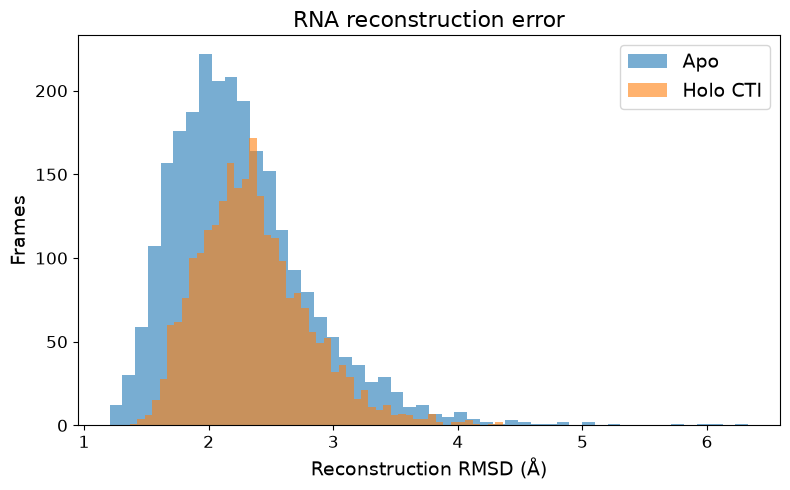

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(rmsd_apo_RNA, bins=50, alpha=0.6, label='Apo')
ax.hist(rmsd_holo_RNA, bins=50, alpha=0.6, label=f'Holo {holo_state}')
ax.set_xlabel('Reconstruction RMSD (Å)')
ax.set_ylabel('Frames')
ax.set_title('RNA reconstruction error')
ax.legend()
fig.tight_layout()
fig.savefig(output_dir / 'reconstruction_rmsd.png', dpi=150)
plt.show()

## Latent-space distribution

This shows whether apo and holo occupy distinct, overlapping, or connected regions of the learned two-dimensional space.

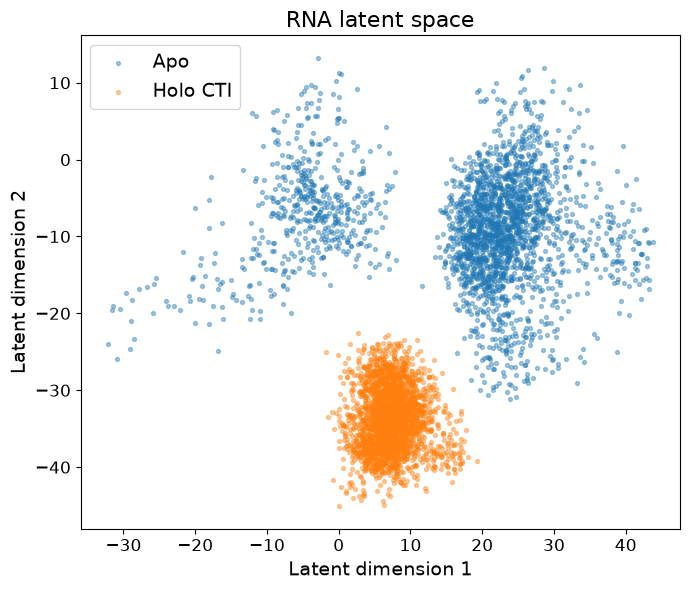

In [9]:
encoded_apo_RNA = analysis_RNA.get_encoded('apo').detach().cpu().numpy()
encoded_holo_RNA = analysis_RNA.get_encoded('holo').detach().cpu().numpy()

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(encoded_apo_RNA[:, 0], encoded_apo_RNA[:, 1], s=8, alpha=0.4, label='Apo')
ax.scatter(encoded_holo_RNA[:, 0], encoded_holo_RNA[:, 1], s=8, alpha=0.4, label=f'Holo {holo_state}')
ax.set_xlabel('Latent dimension 1')
ax.set_ylabel('Latent dimension 2')
ax.set_title('RNA latent space')
ax.legend()
fig.tight_layout()
fig.savefig(output_dir / 'latent_space.png', dpi=150)
plt.show()

## Radius of gyration

Compare compactness before and after reconstruction.

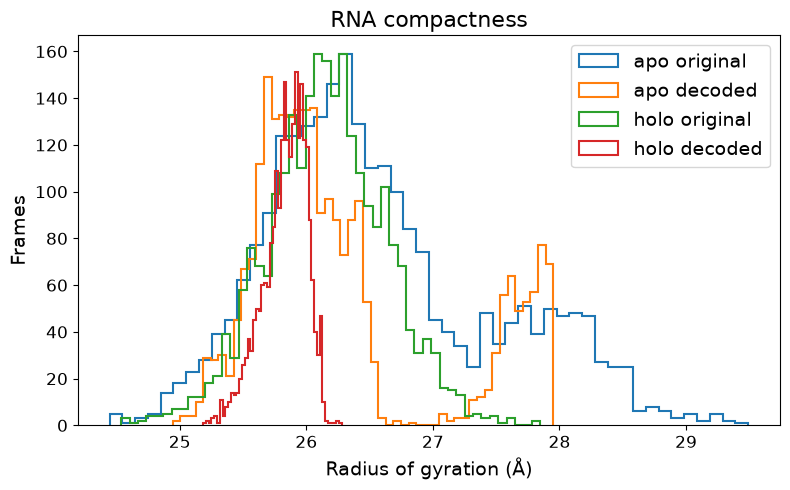

In [10]:
def radius_of_gyration_RNA(coords):
    centered = coords - coords.mean(axis=1, keepdims=True)
    return np.sqrt(np.mean(np.sum(centered ** 2, axis=2), axis=1))

compactness_RNA = {}
for key in ['apo', 'holo']:
    original = analysis_RNA.get_dataset(key, scale=True).detach().cpu().numpy()
    decoded = analysis_RNA.get_decoded(key, scale=True).detach().cpu().numpy()
    compactness_RNA[(key, 'original')] = radius_of_gyration_RNA(original)
    compactness_RNA[(key, 'decoded')] = radius_of_gyration_RNA(decoded)

fig, ax = plt.subplots(figsize=(8, 5))
for (key, kind), values in compactness_RNA.items():
    ax.hist(values, bins=50, histtype='step', linewidth=1.5, label=f'{key} {kind}')
ax.set_xlabel('Radius of gyration (Å)')
ax.set_ylabel('Frames')
ax.set_title('RNA compactness')
ax.legend()
fig.tight_layout()
fig.savefig(output_dir / 'radius_of_gyration.png', dpi=150)
plt.show()

## Generate an apo-to-holo path

The closest-to-centroid structure from each latent ensemble is used as an endpoint, making the result reproducible. This is a direct linear path because physics loss and DOPE are not being used.

In [18]:
apo_center_RNA = encoded_apo_RNA.mean(axis=0)
holo_center_RNA = encoded_holo_RNA.mean(axis=0)
apo_index_RNA = np.linalg.norm(encoded_apo_RNA - apo_center_RNA, axis=1).argmin()
holo_index_RNA = np.linalg.norm(encoded_holo_RNA - holo_center_RNA, axis=1).argmin()

start_RNA = encoded_apo_RNA[apo_index_RNA]
end_RNA = encoded_holo_RNA[holo_index_RNA]
number_of_intermediates_RNA = 15
latent_path_RNA = oversample(np.asarray([start_RNA, end_RNA]),  pts=number_of_intermediates_RNA)

path_dir_RNA = output_dir / 'linear_apo_to_holo_path'
path_dir_RNA.mkdir(parents=True, exist_ok=True)
generated_path_RNA = analysis_RNA.generate(crd=latent_path_RNA, pdb_path=path_dir_RNA)
connected_pdbs_RNA = add_connect_directory_RNA(path_dir_RNA)

print('Apo endpoint frame:', int(apo_index_RNA))
print('Holo endpoint frame:', int(holo_index_RNA))
print('Generated path structures:', len(latent_path_RNA))
print('PDB files with CONECT records:', len(connected_pdbs_RNA))
print('Path directory:', path_dir_RNA)

Generating pdb files: 100%|██████████| 17/17 [00:00<00:00, 60.94it/s]


Apo endpoint frame: 1935
Holo endpoint frame: 241
Generated path structures: 17
PDB files with CONECT records: 17
Path directory: /home/naeim/Workspace/Edinburgh/GitHub/molearn/examples/analysis_RNA_CTI_LUM_CTI/linear_apo_to_holo_path


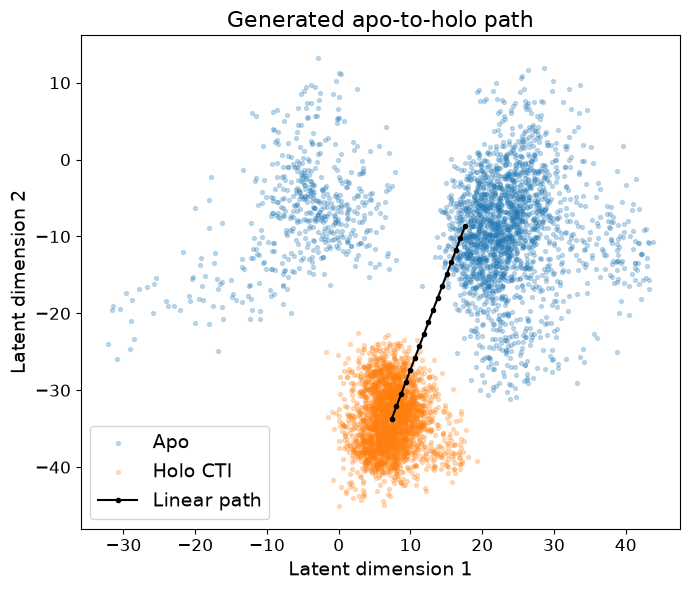

In [19]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(encoded_apo_RNA[:, 0], encoded_apo_RNA[:, 1], s=8, alpha=0.25, label='Apo')
ax.scatter(encoded_holo_RNA[:, 0], encoded_holo_RNA[:, 1], s=8, alpha=0.25, label=f'Holo {holo_state}')
ax.plot(latent_path_RNA[:, 0], latent_path_RNA[:, 1], 'k.-', label='Linear path')
ax.set_xlabel('Latent dimension 1')
ax.set_ylabel('Latent dimension 2')
ax.set_title('Generated apo-to-holo path')
ax.legend()
fig.tight_layout()
fig.savefig(output_dir / 'linear_path.png', dpi=150)
plt.show()

## Coarse-grained bond-distance validation

Compare every connection in the generated path with the distances observed in the aligned apo and holo ensembles. The shaded region is the 5th--95th percentile reference interval; path values outside it indicate locally unusual geometry. These are reduced-representation connections, not an all-atom force-field topology.

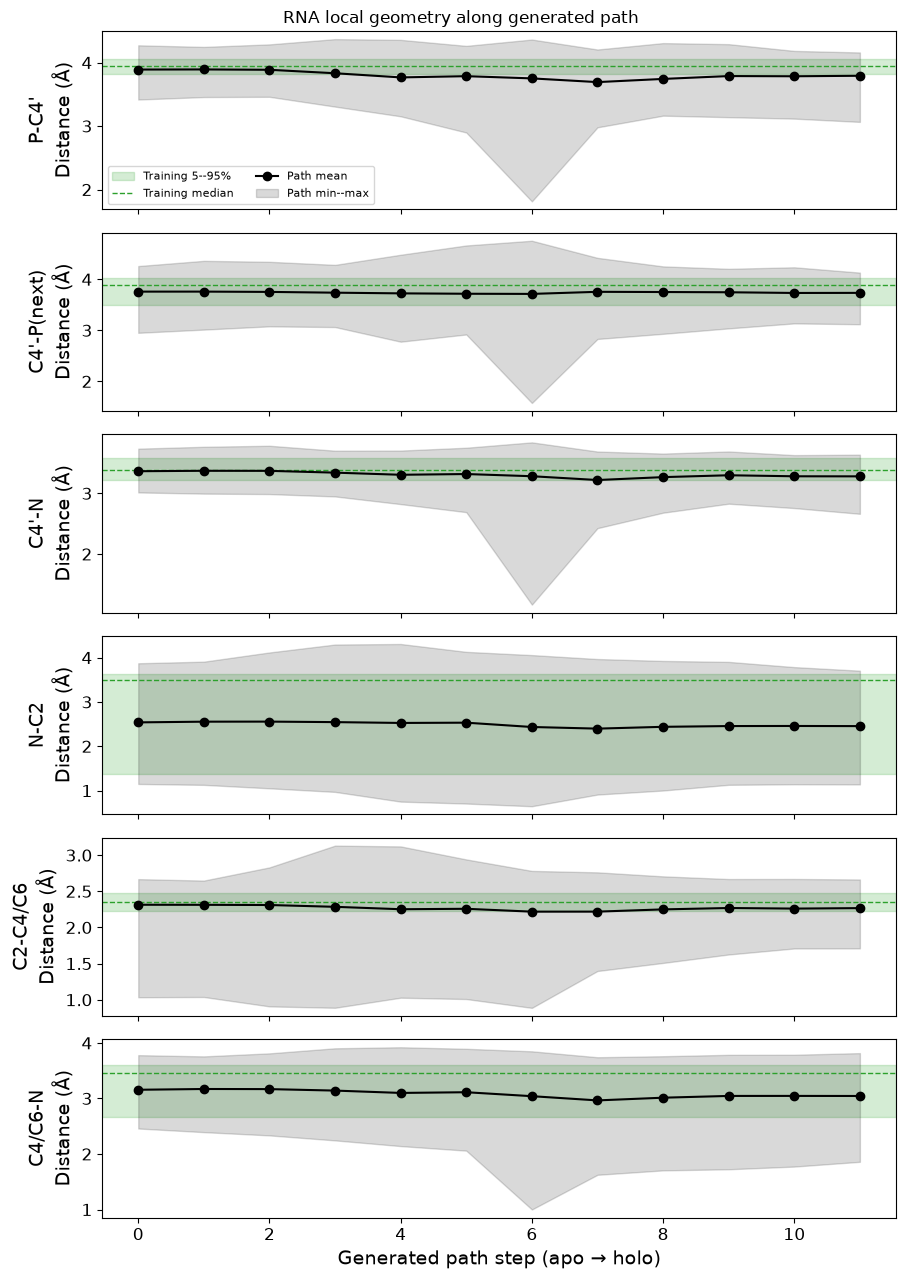

Bond-distance figure: /home/naeim/Workspace/Edinburgh/GitHub/molearn/examples/analysis_RNA_CTI_LUM_CTI/bond_distances_path.png
Bond-distance table: /home/naeim/Workspace/Edinburgh/GitHub/molearn/examples/analysis_RNA_CTI_LUM_CTI/bond_distances_path.csv


In [13]:
atominfo_RNA = data_apo_RNA.get_atominfo()
residues_RNA = []
residue_lookup_RNA = {}
for atom_index_RNA, (atom_name_RNA, resname_RNA, resid_RNA) in enumerate(atominfo_RNA):
    key_RNA = (int(resid_RNA), str(resname_RNA))
    if key_RNA not in residue_lookup_RNA:
        residue_lookup_RNA[key_RNA] = {}
        residues_RNA.append((key_RNA, residue_lookup_RNA[key_RNA]))
    residue_lookup_RNA[key_RNA][str(atom_name_RNA)] = atom_index_RNA

bond_indices_RNA = {
    "P-C4'": [],
    "C4'-P(next)": [],
    "C4'-N": [],
    "N-C2": [],
    "C2-C4/C6": [],
    "C4/C6-N": [],
}
for residue_number_RNA, (_, atoms_RNA) in enumerate(residues_RNA):
    base_n_RNA = atoms_RNA.get('N9', atoms_RNA.get('N1'))
    base_outer_RNA = atoms_RNA.get('C6', atoms_RNA.get('C4'))
    pairs_RNA = {
        "P-C4'": (atoms_RNA.get('P'), atoms_RNA.get("C4'")),
        "C4'-N": (atoms_RNA.get("C4'"), base_n_RNA),
        "N-C2": (base_n_RNA, atoms_RNA.get('C2')),
        "C2-C4/C6": (atoms_RNA.get('C2'), base_outer_RNA),
        "C4/C6-N": (base_outer_RNA, base_n_RNA),
    }
    for label_RNA, pair_RNA in pairs_RNA.items():
        if None not in pair_RNA:
            bond_indices_RNA[label_RNA].append(pair_RNA)
    if residue_number_RNA + 1 < len(residues_RNA):
        next_atoms_RNA = residues_RNA[residue_number_RNA + 1][1]
        pair_RNA = (atoms_RNA.get("C4'"), next_atoms_RNA.get('P'))
        if None not in pair_RNA:
            bond_indices_RNA["C4'-P(next)"].append(pair_RNA)

def bond_distances_RNA(coords_RNA, pairs_RNA):
    first_RNA = np.asarray([pair_RNA[0] for pair_RNA in pairs_RNA])
    second_RNA = np.asarray([pair_RNA[1] for pair_RNA in pairs_RNA])
    return np.linalg.norm(
        coords_RNA[:, first_RNA, :] - coords_RNA[:, second_RNA, :], axis=2
    )

reference_coords_RNA = np.concatenate([
    analysis_RNA.get_dataset('apo', scale=True).detach().cpu().numpy(),
    analysis_RNA.get_dataset('holo', scale=True).detach().cpu().numpy(),
])
reference_bonds_RNA = {
    label_RNA: bond_distances_RNA(reference_coords_RNA, pairs_RNA)
    for label_RNA, pairs_RNA in bond_indices_RNA.items()
}
path_bonds_RNA = {
    label_RNA: bond_distances_RNA(generated_path_RNA, pairs_RNA)
    for label_RNA, pairs_RNA in bond_indices_RNA.items()
}

fig, axes = plt.subplots(len(bond_indices_RNA), 1, figsize=(9, 13), sharex=True)
path_steps_RNA = np.arange(len(generated_path_RNA))
bond_rows_RNA = []
for axis_RNA, label_RNA in zip(axes, bond_indices_RNA):
    reference_values_RNA = reference_bonds_RNA[label_RNA].ravel()
    low_RNA, median_RNA, high_RNA = np.percentile(reference_values_RNA, [5, 50, 95])
    path_values_RNA = path_bonds_RNA[label_RNA]
    path_mean_RNA = path_values_RNA.mean(axis=1)
    axis_RNA.axhspan(low_RNA, high_RNA, alpha=0.2, color='tab:green', label='Training 5--95%')
    axis_RNA.axhline(median_RNA, linestyle='--', color='tab:green', linewidth=1, label='Training median')
    axis_RNA.plot(path_steps_RNA, path_mean_RNA, 'o-', color='black', label='Path mean')
    axis_RNA.fill_between(
        path_steps_RNA, path_values_RNA.min(axis=1), path_values_RNA.max(axis=1),
        alpha=0.15, color='black', label='Path min--max'
    )
    axis_RNA.set_ylabel(f'{label_RNA}\nDistance (Å)')
    for step_RNA, values_RNA in enumerate(path_values_RNA):
        bond_rows_RNA.append({
            'path_step': step_RNA, 'bond_type': label_RNA,
            'path_mean_A': float(values_RNA.mean()),
            'path_min_A': float(values_RNA.min()),
            'path_max_A': float(values_RNA.max()),
            'reference_p05_A': float(low_RNA),
            'reference_median_A': float(median_RNA),
            'reference_p95_A': float(high_RNA),
            'fraction_outside_reference_5_95': float(
                ((values_RNA < low_RNA) | (values_RNA > high_RNA)).mean()
            ),
        })
axes[0].legend(ncols=2, fontsize=8)
axes[-1].set_xlabel('Generated path step (apo → holo)')
fig.suptitle('RNA local geometry along generated path')
fig.tight_layout()
fig.savefig(output_dir / 'bond_distances_path.png', dpi=150)
plt.show()

bond_csv_RNA = output_dir / 'bond_distances_path.csv'
with open(bond_csv_RNA, 'w', newline='') as outfile_RNA:
    writer_RNA = csv.DictWriter(outfile_RNA, fieldnames=bond_rows_RNA[0].keys())
    writer_RNA.writeheader()
    writer_RNA.writerows(bond_rows_RNA)
print('Bond-distance figure:', output_dir / 'bond_distances_path.png')
print('Bond-distance table:', bond_csv_RNA)

## Outputs

The analysis directory contains the RMSD and bond-distance summary CSV files, plots, and generated PDB path. In `bond_distances_path.png`, path means should remain near the training median and the path min--max should largely overlap the green reference interval. Because this model has no physics loss, inspect generated structures carefully and do not interpret the linear path as an energy-minimized transition.